In [2]:
import pandas as pd

RTA_PATH = "RTA Dataset.csv"

rta_df = pd.read_csv(RTA_PATH)

# Convert common missing-value placeholders to actual NaN
rta_df = rta_df.replace(
    to_replace=r"(?i)^\s*(na|n/a|unknown|)\s*$",
    value=pd.NA,
    regex=True
)

print("Dataset shape:", rta_df.shape)

print("\nMissing values:")
missing = (
    rta_df.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_count")
)

missing["missing_percentage"] = (
    missing["missing_count"] / len(rta_df) * 100
).round(2)

display(missing[missing["missing_count"] > 0])

print("\nTarget distribution:")
display(
    rta_df["Accident_severity"]
    .value_counts()
    .to_frame("count")
)

Dataset shape: (12316, 32)

Missing values:


,missing_count,missing_percentage
Service_year_of_vehicle,6811,55.30
Age_band_of_casualty,4443,36.08
Casualty_severity,4443,36.08
Casualty_class,4443,36.08
Sex_of_casualty,4443,36.08
Defect_of_vehicle,4427,35.95
Work_of_casuality,3217,26.12
Fitness_of_casuality,2635,21.39
Age_band_of_driver,1548,12.57
Types_of_Junction,1078,8.75



Target distribution:


,count
Accident_severity,
Slight Injury,10415
Serious Injury,1743
Fatal injury,158


In [3]:
# Target distribution
print("Target distribution:")
print(
    rta_df["Accident_severity"]
    .value_counts()
)

print("\nTarget distribution percentages:")
print(
    rta_df["Accident_severity"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# Inspect data types
print("\nData types:")
display(rta_df.dtypes.to_frame("data_type"))

# Inspect unique values in selected columns
columns_to_inspect = [
    "Accident_severity",
    "Service_year_of_vehicle",
    "Defect_of_vehicle",
    "Age_band_of_driver",
    "Driving_experience",
    "Weather_conditions",
    "Road_surface_type",
    "Cause_of_accident"
]

for column in columns_to_inspect:
    print(f"\n{column}")
    print(rta_df[column].value_counts(dropna=False).head(15))

Target distribution:
Accident_severity
Slight Injury     10415
Serious Injury     1743
Fatal injury        158
Name: count, dtype: int64

Target distribution percentages:
Accident_severity
Slight Injury     84.56
Serious Injury    14.15
Fatal injury       1.28
Name: proportion, dtype: float64

Data types:


,data_type
Time,str
Day_of_week,str
Age_band_of_driver,str
Sex_of_driver,str
Educational_level,str
Vehicle_driver_relation,str
Driving_experience,str
Type_of_vehicle,str
Owner_of_vehicle,str
Service_year_of_vehicle,str



Accident_severity
Accident_severity
Slight Injury     10415
Serious Injury     1743
Fatal injury        158
Name: count, dtype: int64

Service_year_of_vehicle
Service_year_of_vehicle
NaN           6811
2-5yrs        1792
Above 10yr    1324
5-10yrs       1280
1-2yr          827
Below 1yr      282
Name: count, dtype: int64

Defect_of_vehicle
Defect_of_vehicle
No defect    7777
NaN          4427
7              76
5              36
Name: count, dtype: int64

Age_band_of_driver
Age_band_of_driver
18-30       4271
31-50       4087
Over 51     1585
NaN         1548
Under 18     825
Name: count, dtype: int64

Driving_experience
Driving_experience
5-10yr        3363
2-5yr         2613
Above 10yr    2262
1-2yr         1756
Below 1yr     1342
NaN            862
No Licence     118
Name: count, dtype: int64

Weather_conditions
Weather_conditions
Normal               10063
Raining               1331
Other                  296
NaN                    292
Cloudy                 125
Windy              

In [ ]:

# Standardize whitespace and common missing-value placeholders
missing_placeholders = [
    "na",
    "n/a",
    "nan",
    "none",
    "null",
    ""
]

for col in rta_df.select_dtypes(include=["object", "str"]).columns:

    rta_df[col] = rta_df[col].apply(
        lambda value: (
            np.nan
            if isinstance(value, str)
            and value.strip().lower() in missing_placeholders
            else value.strip() if isinstance(value, str)
            else value
        )
    )

print("\nDataset shape:", rta_df.shape)



Dataset shape: (12316, 32)

Missing values after normalization:


In [8]:
target = "Accident_severity"

class_counts = rta_df[target].value_counts(dropna=False)

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": (
        class_counts / len(rta_df) * 100
    ).round(2)
})

print("ACCIDENT SEVERITY DISTRIBUTION")

print(class_distribution)

ACCIDENT SEVERITY DISTRIBUTION
                   Count  Percentage
Accident_severity                   
Slight Injury      10415       84.56
Serious Injury      1743       14.15
Fatal injury         158        1.28


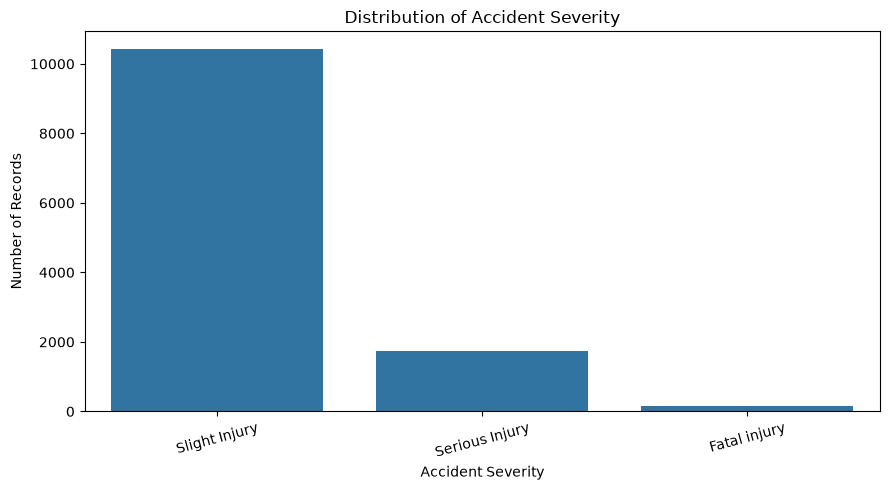

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.countplot(
    data=rta_df,
    x=target,
    order=rta_df[target].value_counts().index
)

plt.title("Distribution of Accident Severity")
plt.xlabel("Accident Severity")
plt.ylabel("Number of Records")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [17]:
feature_audit = []

for col in rta_df.columns:

    feature_audit.append({
        "Feature": col,
        "Data_Type": str(rta_df[col].dtype),
        "Unique_Values": rta_df[col].nunique(dropna=True),
        "Missing_Count": rta_df[col].isna().sum(),
        "Missing_Percentage": round(
            rta_df[col].isna().mean() * 100, 2
        )
    })

feature_audit_df = pd.DataFrame(feature_audit)

print(
    feature_audit_df.to_string(index=False)
)

                    Feature Data_Type  Unique_Values  Missing_Count  Missing_Percentage
                       Time       str           1074              0                0.00
                Day_of_week       str              7              0                0.00
         Age_band_of_driver       str              4           1548               12.57
              Sex_of_driver       str              2            178                1.45
          Educational_level       str              6            841                6.83
    Vehicle_driver_relation       str              3            593                4.81
         Driving_experience       str              6            862                7.00
            Type_of_vehicle       str             17            950                7.71
           Owner_of_vehicle       str              4            482                3.91
    Service_year_of_vehicle       str              5           6811               55.30
          Defect_of_vehicle     

In [18]:
target = "Accident_severity"

# Exclude the target and the potentially leakage-prone casualty severity field
excluded_features = [
    "Accident_severity",
    "Casualty_severity"
]

X = rta_df.drop(columns=excluded_features)
y = rta_df[target]

print("Target:", target)
print("Number of predictors:", X.shape[1])
print("Number of target classes:", y.nunique())
print("\nPredictor columns:")
print(X.columns.tolist())

Target: Accident_severity
Number of predictors: 30
Number of target classes: 3

Predictor columns:
['Time', 'Day_of_week', 'Age_band_of_driver', 'Sex_of_driver', 'Educational_level', 'Vehicle_driver_relation', 'Driving_experience', 'Type_of_vehicle', 'Owner_of_vehicle', 'Service_year_of_vehicle', 'Defect_of_vehicle', 'Area_accident_occured', 'Lanes_or_Medians', 'Road_allignment', 'Types_of_Junction', 'Road_surface_type', 'Road_surface_conditions', 'Light_conditions', 'Weather_conditions', 'Type_of_collision', 'Number_of_vehicles_involved', 'Number_of_casualties', 'Vehicle_movement', 'Casualty_class', 'Sex_of_casualty', 'Age_band_of_casualty', 'Work_of_casuality', 'Fitness_of_casuality', 'Pedestrian_movement', 'Cause_of_accident']


In [19]:
feature_summary = pd.DataFrame({
    "Data_Type": X.dtypes.astype(str),
    "Unique_Values": X.nunique(dropna=True),
    "Missing_Count": X.isna().sum(),
    "Missing_Percentage": (X.isna().mean() * 100).round(2)
})

feature_summary = feature_summary.sort_values(
    by="Unique_Values",
    ascending=False
)

print(feature_summary.to_string())

                            Data_Type  Unique_Values  Missing_Count  Missing_Percentage
Time                              str           1074              0                0.00
Cause_of_accident                 str             19             25                0.20
Type_of_vehicle                   str             17            950                7.71
Area_accident_occured             str             12            261                2.12
Vehicle_movement                  str             12            396                3.22
Road_allignment                   str              9            142                1.15
Pedestrian_movement               str              9              0                0.00
Type_of_collision                 str              9            169                1.37
Weather_conditions                str              8            292                2.37
Number_of_casualties            int64              8              0                0.00
Day_of_week                     

In [20]:
categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

for col in categorical_features:
    print(f"\n{'=' * 70}")
    print(f"FEATURE: {col}")
    print("=" * 70)

    distribution = pd.crosstab(
        rta_df[col],
        y,
        normalize="index"
    ) * 100

    print(distribution.round(1).to_string())


FEATURE: Time
Accident_severity  Fatal injury  Serious Injury  Slight Injury
Time                                                          
0:01:00                     0.0            22.2           77.8
0:02:00                     0.0             0.0          100.0
0:03:00                     0.0             0.0          100.0
0:04:00                     0.0           100.0            0.0
0:06:00                     0.0             0.0          100.0
0:08:00                     0.0             0.0          100.0
0:09:00                     0.0             0.0          100.0
0:10:00                    17.9            28.6           53.6
0:11:00                     0.0             0.0          100.0
0:15:00                     0.0            14.3           85.7
0:17:00                     0.0             0.0          100.0
0:18:00                     0.0           100.0            0.0
0:19:00                     0.0             0.0          100.0
0:20:00                     0.0         

In [21]:
# Convert Time to datetime
rta_df["Time_parsed"] = pd.to_datetime(
    rta_df["Time"],
    format="%H:%M:%S",
    errors="coerce"
)

# Extract hour
rta_df["Accident_hour"] = rta_df["Time_parsed"].dt.hour

# Create time-of-day categories
def classify_time_of_day(hour):
    if pd.isna(hour):
        return np.nan
    elif 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 17:
        return "Afternoon"
    elif 17 <= hour < 21:
        return "Evening"
    else:
        return "Night"

rta_df["Time_of_day"] = rta_df["Accident_hour"].apply(
    classify_time_of_day
)

print(rta_df[[
    "Time",
    "Accident_hour",
    "Time_of_day",
    "Accident_severity"
]].head(10))

print("\nInvalid time values:", rta_df["Accident_hour"].isna().sum())
print("\nTime-of-day distribution:")
print(rta_df["Time_of_day"].value_counts(dropna=False))

       Time  Accident_hour Time_of_day Accident_severity
0  17:02:00             17     Evening     Slight Injury
1  17:02:00             17     Evening     Slight Injury
2  17:02:00             17     Evening    Serious Injury
3   1:06:00              1       Night     Slight Injury
4   1:06:00              1       Night     Slight Injury
5  14:15:00             14   Afternoon     Slight Injury
6  17:30:00             17     Evening     Slight Injury
7  17:20:00             17     Evening     Slight Injury
8  17:20:00             17     Evening     Slight Injury
9  17:20:00             17     Evening    Serious Injury

Invalid time values: 0

Time-of-day distribution:
Time_of_day
Afternoon    3897
Evening      3496
Morning      3312
Night        1611
Name: count, dtype: int64


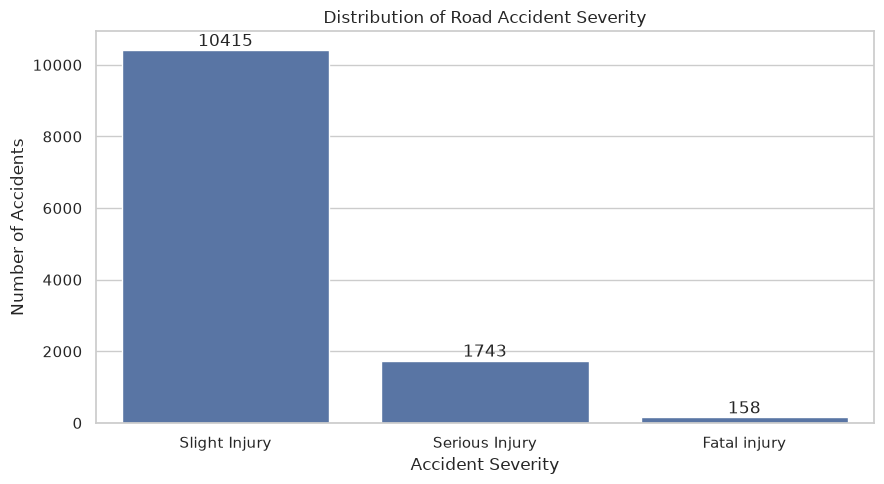

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")

plt.figure(figsize=(9, 5))

severity_order = rta_df["Accident_severity"].value_counts().index

ax = sns.countplot(
    data=rta_df,
    x="Accident_severity",
    order=severity_order
)

plt.title("Distribution of Road Accident Severity")
plt.xlabel("Accident Severity")
plt.ylabel("Number of Accidents")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()
plt.show()

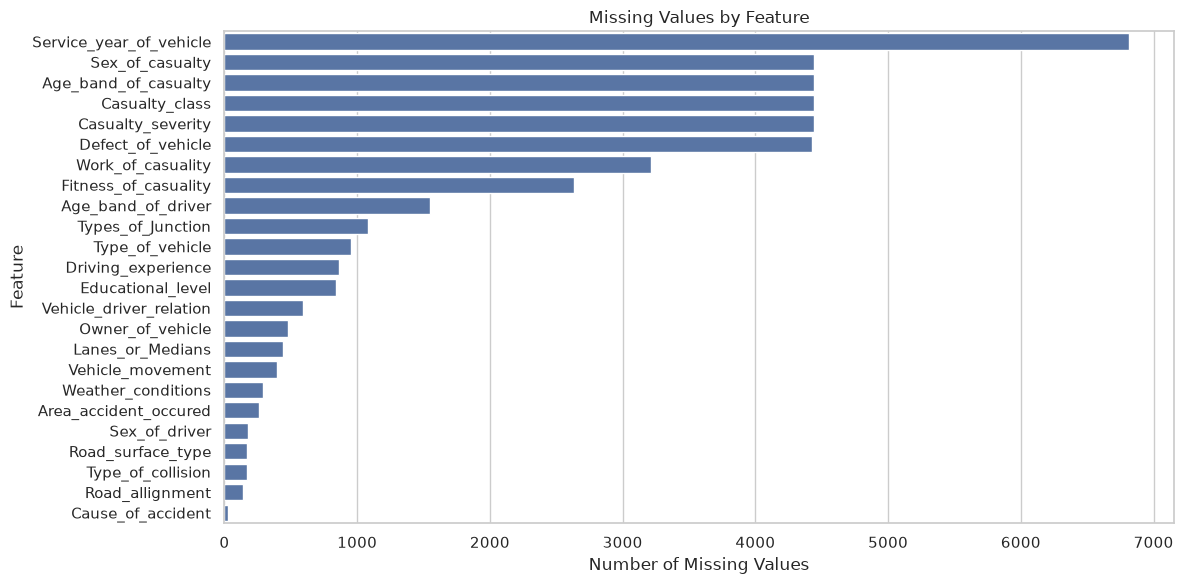

In [23]:
missing = (
    rta_df.isna()
    .sum()
    .sort_values(ascending=False)
)

missing = missing[missing > 0]

plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing.values,
    y=missing.index
)

plt.title("Missing Values by Feature")
plt.xlabel("Number of Missing Values")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

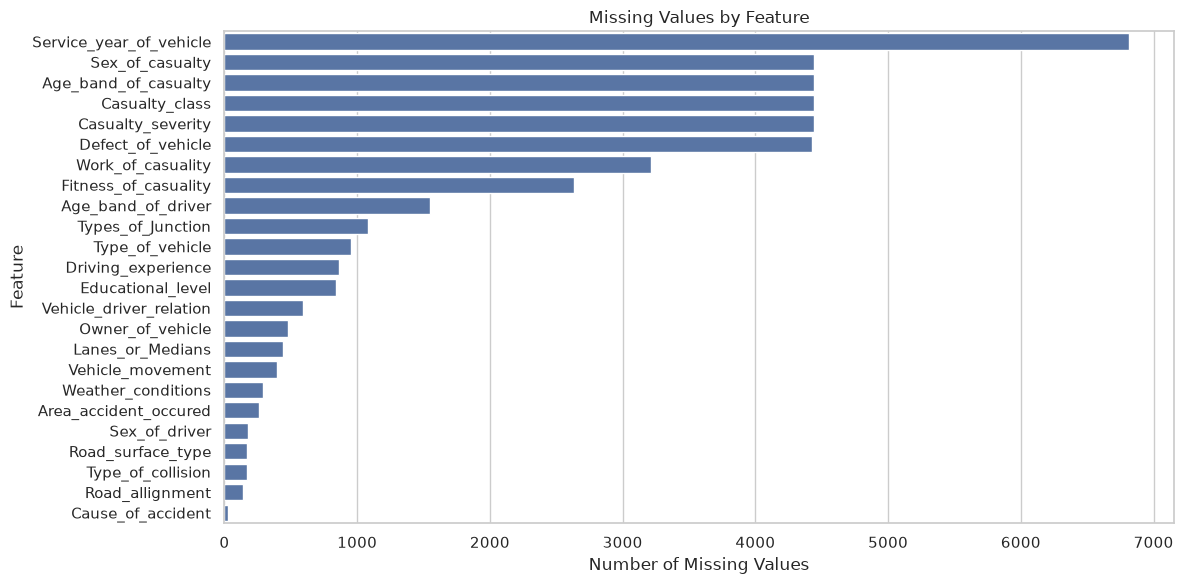

In [24]:
missing = (
    rta_df.isna()
    .sum()
    .sort_values(ascending=False)
)

missing = missing[missing > 0]

plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing.values,
    y=missing.index
)

plt.title("Missing Values by Feature")
plt.xlabel("Number of Missing Values")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

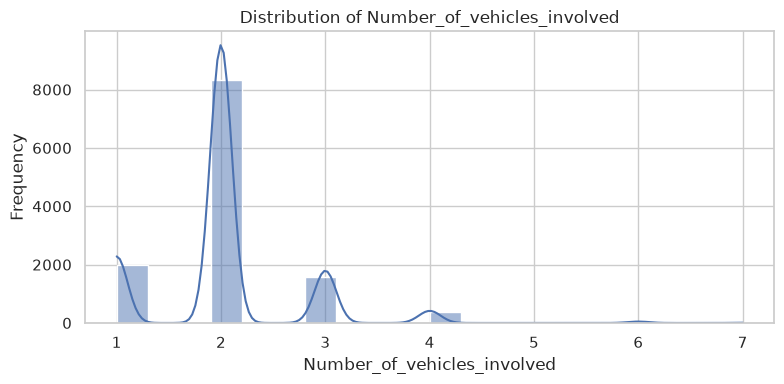

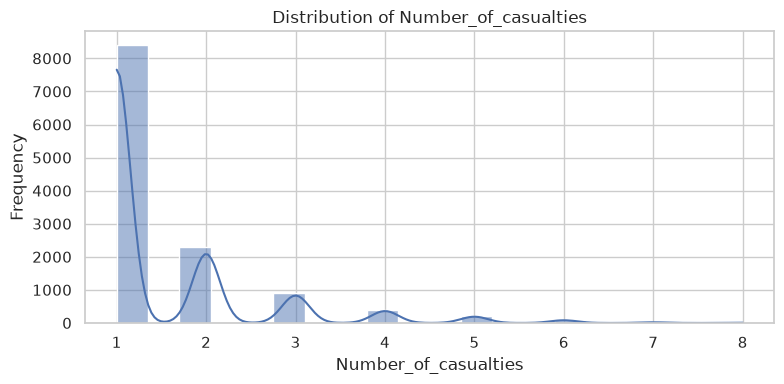

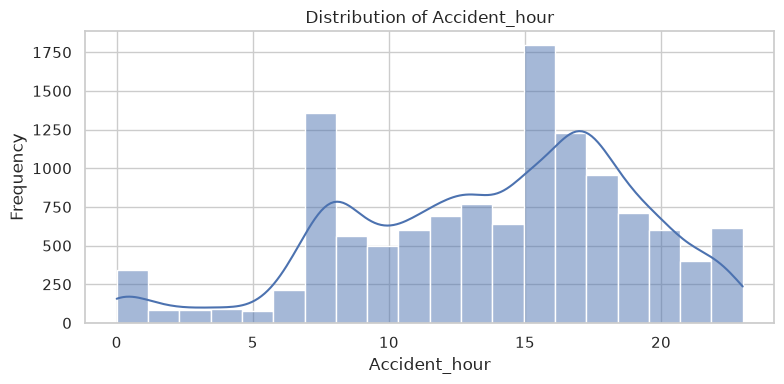

In [25]:
numeric_features = [
    "Number_of_vehicles_involved",
    "Number_of_casualties",
    "Accident_hour"
]

available_numeric = [
    col for col in numeric_features
    if col in rta_df.columns
]

for col in available_numeric:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=rta_df,
        x=col,
        bins=20,
        kde=True
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

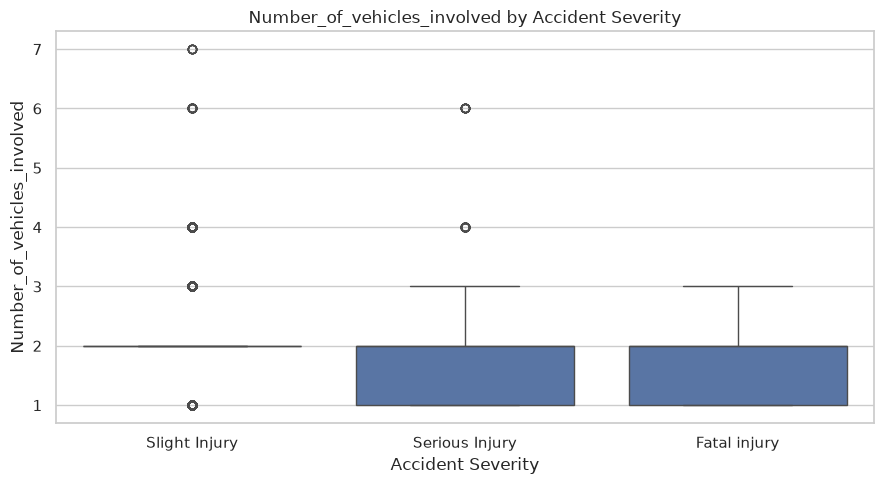

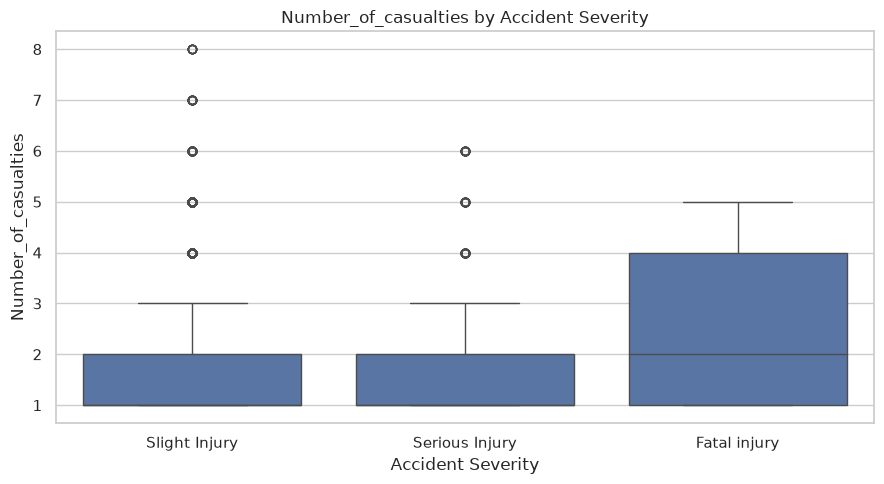

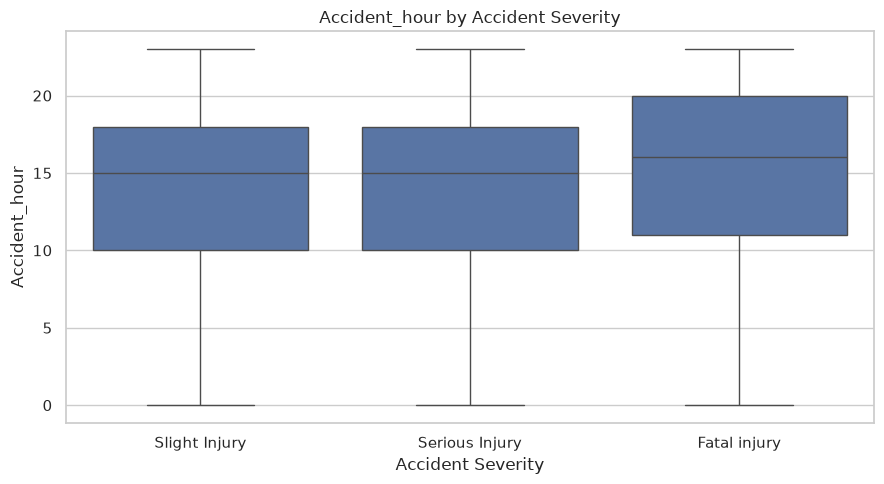

In [26]:
for col in available_numeric:
    plt.figure(figsize=(9, 5))

    sns.boxplot(
        data=rta_df,
        x="Accident_severity",
        y=col
    )

    plt.title(f"{col} by Accident Severity")
    plt.xlabel("Accident Severity")
    plt.ylabel(col)

    plt.tight_layout()
    plt.show()

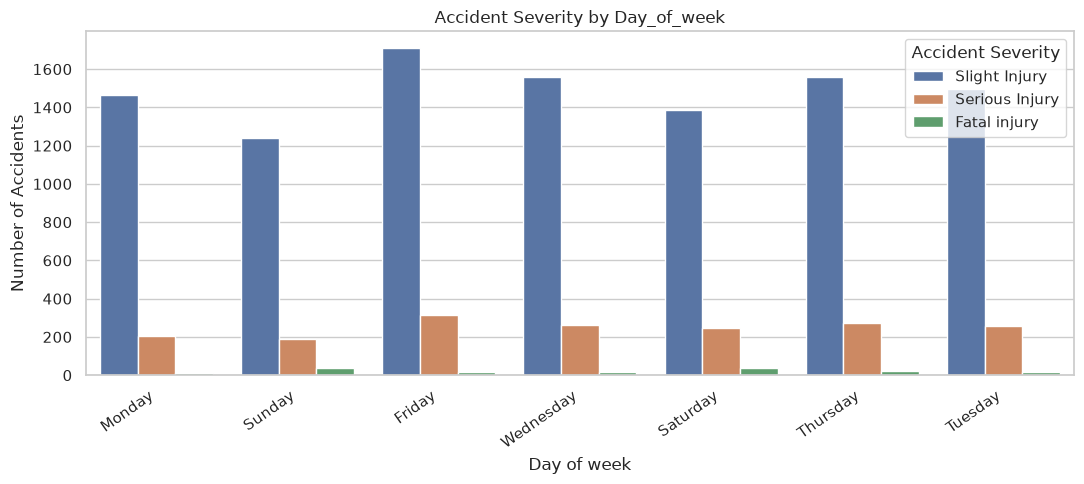

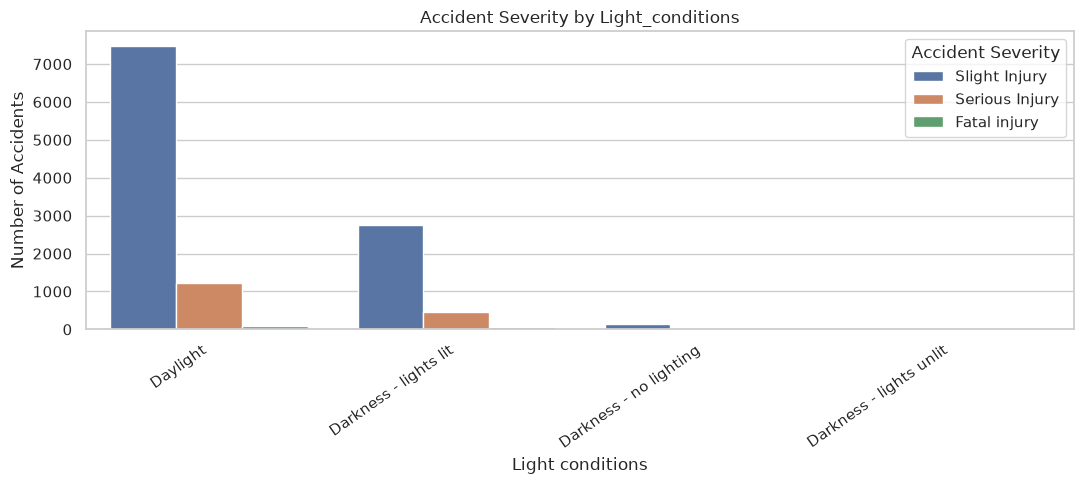

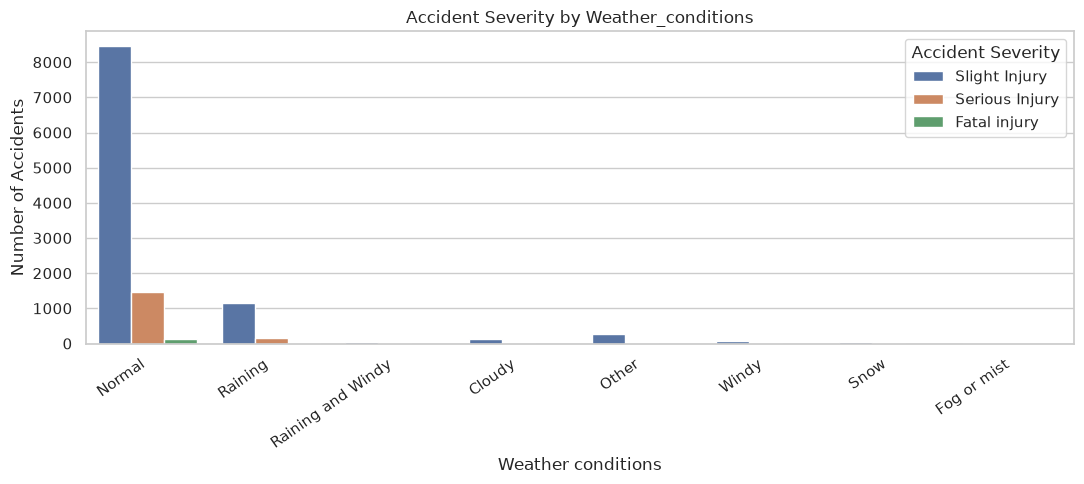

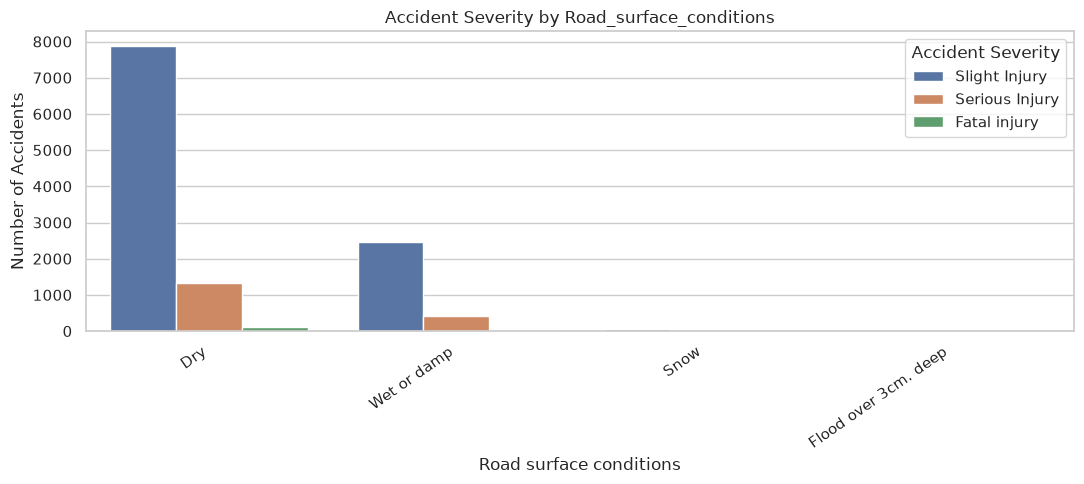

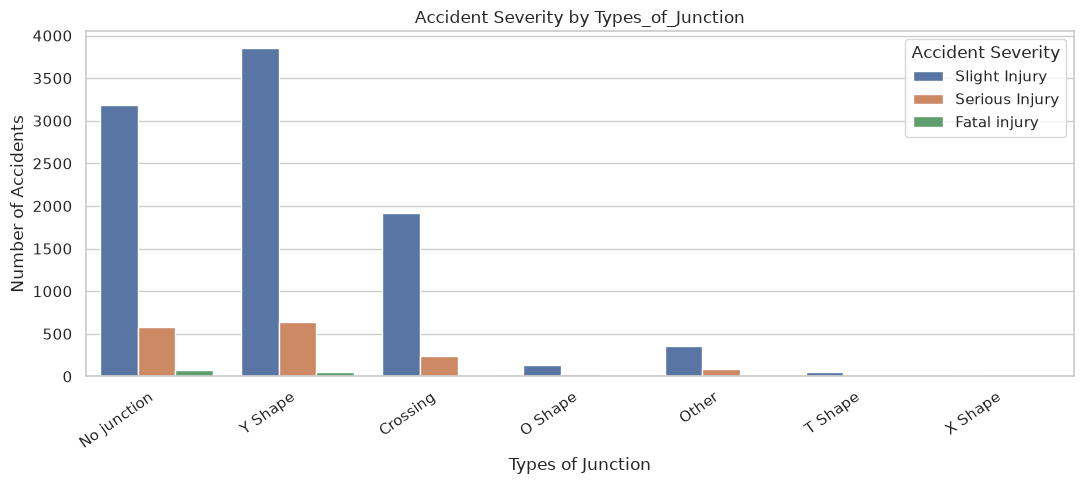

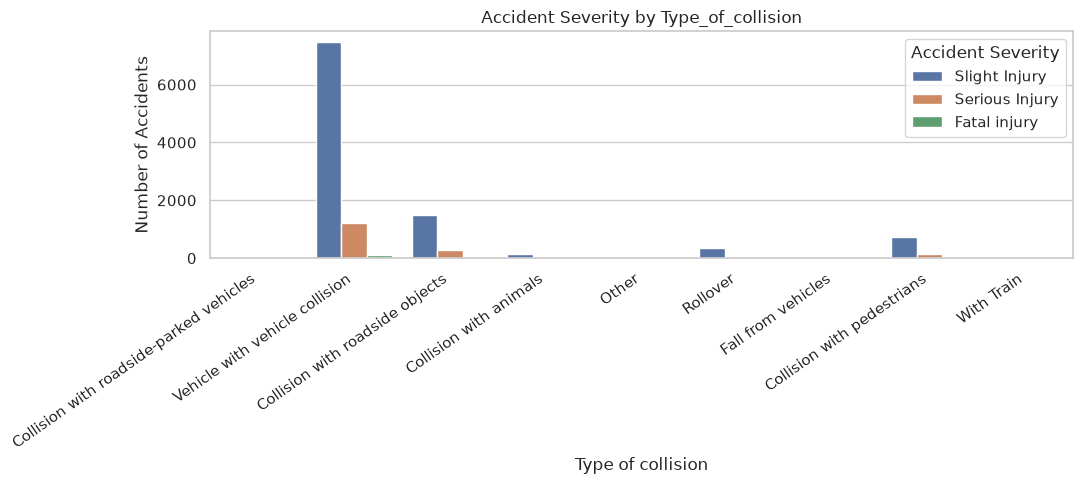

In [27]:
categorical_to_plot = [
    "Day_of_week",
    "Light_conditions",
    "Weather_conditions",
    "Road_surface_conditions",
    "Types_of_Junction",
    "Type_of_collision"
]

for col in categorical_to_plot:
    if col not in rta_df.columns:
        continue

    plt.figure(figsize=(11, 5))

    sns.countplot(
        data=rta_df,
        x=col,
        hue="Accident_severity"
    )

    plt.title(f"Accident Severity by {col}")
    plt.xlabel(col.replace("_", " "))
    plt.ylabel("Number of Accidents")
    plt.xticks(rotation=35, ha="right")
    plt.legend(title="Accident Severity")

    plt.tight_layout()
    plt.show()

In [28]:
target = "Accident_severity"

excluded_features = [
    "Casualty_severity",
    "Casualty_class",
    "Sex_of_casualty",
    "Age_band_of_casualty",
    "Work_of_casuality",
    "Fitness_of_casuality",
    "Number_of_casualties",
    "Time",
    "Time_parsed"
]

excluded_features = [
    col for col in excluded_features
    if col in rta_df.columns
]

model_df = rta_df.dropna(subset=[target]).copy()

X = model_df.drop(
    columns=[target] + excluded_features
)

y = model_df[target]

print("FINAL INITIAL FEATURE SET")

print("Dataset shape:", model_df.shape)
print("Number of predictors:", X.shape[1])
print("Number of target classes:", y.nunique())

print("\nExcluded features:")
print(excluded_features)

print("\nSelected features:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

FINAL INITIAL FEATURE SET
Dataset shape: (12316, 35)
Number of predictors: 25
Number of target classes: 3

Excluded features:
['Casualty_severity', 'Casualty_class', 'Sex_of_casualty', 'Age_band_of_casualty', 'Work_of_casuality', 'Fitness_of_casuality', 'Number_of_casualties', 'Time', 'Time_parsed']

Selected features:
['Day_of_week', 'Age_band_of_driver', 'Sex_of_driver', 'Educational_level', 'Vehicle_driver_relation', 'Driving_experience', 'Type_of_vehicle', 'Owner_of_vehicle', 'Service_year_of_vehicle', 'Defect_of_vehicle', 'Area_accident_occured', 'Lanes_or_Medians', 'Road_allignment', 'Types_of_Junction', 'Road_surface_type', 'Road_surface_conditions', 'Light_conditions', 'Weather_conditions', 'Type_of_collision', 'Number_of_vehicles_involved', 'Vehicle_movement', 'Pedestrian_movement', 'Cause_of_accident', 'Accident_hour', 'Time_of_day']

Target distribution:
Accident_severity
Slight Injury     10415
Serious Injury     1743
Fatal injury        158
Name: count, dtype: int64


In [31]:
from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: divide the temporary data equally
# 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("DATASET SPLIT SUMMARY")

print(f"Training set:   {X_train.shape[0]:,} records")
print(f"Validation set: {X_val.shape[0]:,} records")
print(f"Test set:       {X_test.shape[0]:,} records")

print("\nTotal records:", len(X_train) + len(X_val) + len(X_test))

DATASET SPLIT SUMMARY
Training set:   8,621 records
Validation set: 1,847 records
Test set:       1,848 records

Total records: 12316


In [32]:
split_distribution = pd.DataFrame({
    "Full Dataset": y.value_counts(normalize=True) * 100,
    "Training": y_train.value_counts(normalize=True) * 100,
    "Validation": y_val.value_counts(normalize=True) * 100,
    "Test": y_test.value_counts(normalize=True) * 100
}).fillna(0).round(2)

print("TARGET CLASS DISTRIBUTION ACROSS SPLITS (%)")
print(split_distribution.to_string())

TARGET CLASS DISTRIBUTION ACROSS SPLITS (%)
                   Full Dataset  Training  Validation   Test
Accident_severity                                           
Slight Injury             84.56     84.56       84.57  84.58
Serious Injury            14.15     14.15       14.13  14.18
Fatal injury               1.28      1.29        1.30   1.24


In [33]:
print("SPLIT VALIDATION")

print("Training and validation overlap:",
      len(set(X_train.index) & set(X_val.index)))

print("Training and test overlap:",
      len(set(X_train.index) & set(X_test.index)))

print("Validation and test overlap:",
      len(set(X_val.index) & set(X_test.index)))

SPLIT VALIDATION
Training and validation overlap: 0
Training and test overlap: 0
Validation and test overlap: 0


In [34]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

print("NUMERICAL FEATURES")
print(numeric_features)

print("\nCATEGORICAL FEATURES")
print(categorical_features)

print("\nFeature counts:")
print("Numerical:", len(numeric_features))
print("Categorical:", len(categorical_features))
print("Total:", len(numeric_features) + len(categorical_features))

NUMERICAL FEATURES
['Number_of_vehicles_involved', 'Accident_hour']

CATEGORICAL FEATURES
['Day_of_week', 'Age_band_of_driver', 'Sex_of_driver', 'Educational_level', 'Vehicle_driver_relation', 'Driving_experience', 'Type_of_vehicle', 'Owner_of_vehicle', 'Service_year_of_vehicle', 'Defect_of_vehicle', 'Area_accident_occured', 'Lanes_or_Medians', 'Road_allignment', 'Types_of_Junction', 'Road_surface_type', 'Road_surface_conditions', 'Light_conditions', 'Weather_conditions', 'Type_of_collision', 'Vehicle_movement', 'Pedestrian_movement', 'Cause_of_accident', 'Time_of_day']

Feature counts:
Numerical: 2
Categorical: 23
Total: 25


In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [36]:
X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("PREPROCESSING RESULTS")

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal validation shape:", X_val.shape)
print("Processed validation shape:", X_val_processed.shape)

print("\nOriginal test shape:", X_test.shape)
print("Processed test shape:", X_test_processed.shape)


PREPROCESSING RESULTS
Original training shape: (8621, 25)
Processed training shape: (8621, 184)

Original validation shape: (1847, 25)
Processed validation shape: (1847, 184)

Original test shape: (1848, 25)
Processed test shape: (1848, 184)


In [37]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import pandas as pd
import numpy as np

In [38]:
# Convert sparse matrices to dense arrays when necessary
X_train_dense = (
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed
)

X_val_dense = (
    X_val_processed.toarray()
    if hasattr(X_val_processed, "toarray")
    else X_val_processed
)

print("Training matrix:", X_train_dense.shape)
print("Validation matrix:", X_val_dense.shape)

Training matrix: (8621, 184)
Validation matrix: (1847, 184)


In [ ]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

print("Models defined:", len(models))

Models defined: 5


In [ ]:
results = []
trained_models = {}

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

for name, model in models.items():

    print(f"\nTraining: {name}")

    if name == "Logistic Regression":
        model.fit(X_train_processed, y_train)

    elif name == "Gradient Boosting":
        model.fit(
            X_train_dense,
            y_train,
            sample_weight=sample_weights
        )

    else:
        model.fit(X_train_dense, y_train)

    if name in ["Logistic Regression"]:
        y_pred = model.predict(X_val_processed)
    else:
        y_pred = model.predict(X_val_dense)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_val, y_pred),
        "Macro Precision": precision_score(
            y_val, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_val, y_pred, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_val, y_pred, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_val, y_pred, average="weighted", zero_division=0
        )
    })

    trained_models[name] = model

    print(f"Completed: {name}")

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Macro F1",
    ascending=False
)

print("\nBASELINE MODEL COMPARISON")
print("=" * 100)
print(results_df.round(4).to_string(index=False))


Training: Dummy Classifier
Completed: Dummy Classifier

Training: Logistic Regression
Completed: Logistic Regression

Training: Decision Tree
Completed: Decision Tree

Training: Random Forest
Completed: Random Forest

Training: Gradient Boosting
Completed: Gradient Boosting

BASELINE MODEL COMPARISON
              Model  Accuracy  Balanced Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1
  Gradient Boosting    0.5912             0.4637           0.3786        0.4637    0.3616       0.6581
      Decision Tree    0.7396             0.3594           0.3603        0.3594    0.3596       0.7432
Logistic Regression    0.4851             0.4713           0.3617        0.4713    0.3156       0.5711
   Dummy Classifier    0.8457             0.3333           0.2819        0.3333    0.3055       0.7750
      Random Forest    0.8457             0.3333           0.2819        0.3333    0.3055       0.7750


In [ ]:
for name, model in trained_models.items():

    print("\n" + "=" * 75)
    print(f"CLASSIFICATION REPORT: {name}")
    print("=" * 75)

    if name in ["Logistic Regression"]:
        y_pred = model.predict(X_val_processed)
    else:
        y_pred = model.predict(X_val_dense)

    print(classification_report(
        y_val,
        y_pred,
        zero_division=0
    ))


CLASSIFICATION REPORT: Dummy Classifier
                precision    recall  f1-score   support

  Fatal injury       0.00      0.00      0.00        24
Serious Injury       0.00      0.00      0.00       261
 Slight Injury       0.85      1.00      0.92      1562

      accuracy                           0.85      1847
     macro avg       0.28      0.33      0.31      1847
  weighted avg       0.72      0.85      0.77      1847


CLASSIFICATION REPORT: Logistic Regression
                precision    recall  f1-score   support

  Fatal injury       0.03      0.50      0.07        24
Serious Injury       0.18      0.42      0.25       261
 Slight Injury       0.87      0.50      0.63      1562

      accuracy                           0.49      1847
     macro avg       0.36      0.47      0.32      1847
  weighted avg       0.76      0.49      0.57      1847


CLASSIFICATION REPORT: Decision Tree
                precision    recall  f1-score   support

  Fatal injury       0.05     

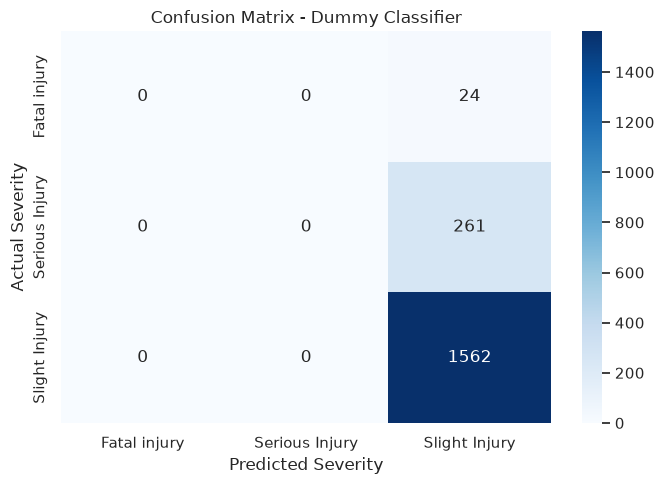

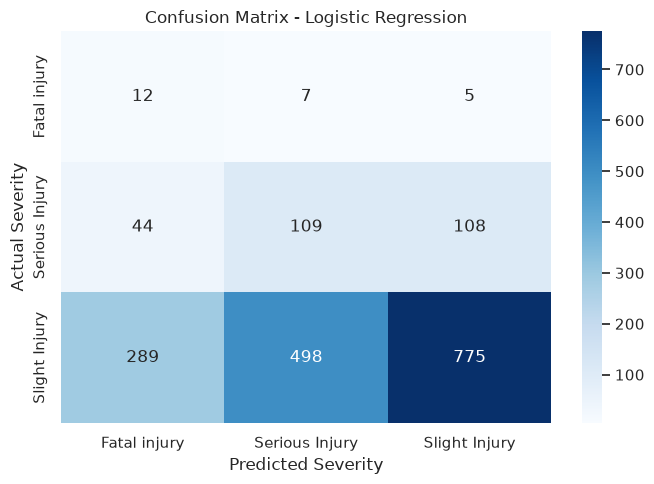

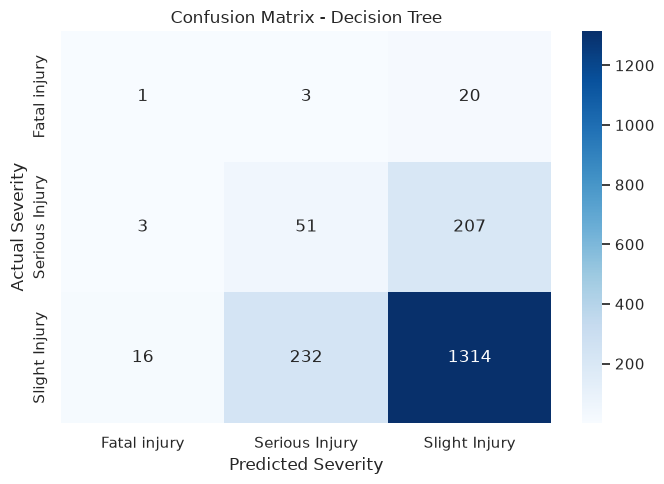

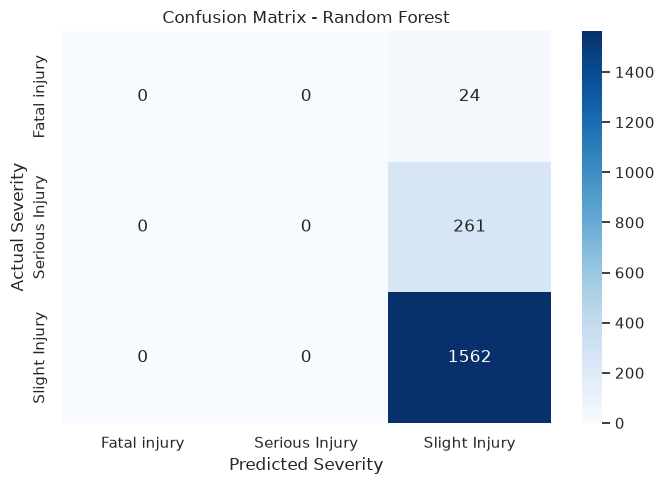

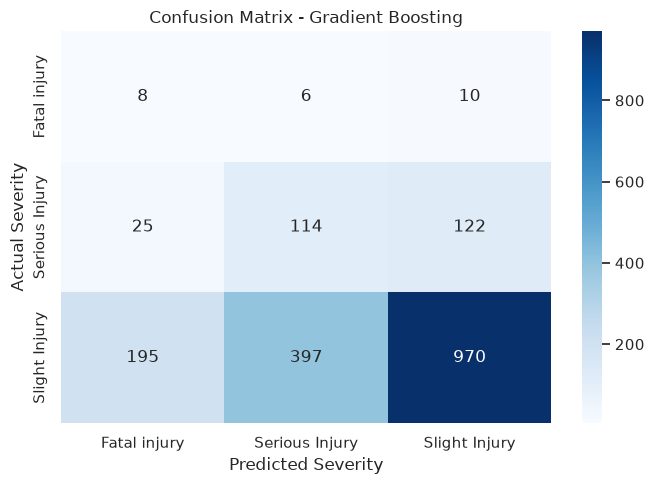

In [ ]:
for name, model in trained_models.items():

    if name in ["Logistic Regression"]:
        y_pred = model.predict(X_val_processed)
    else:
        y_pred = model.predict(X_val_dense)

    cm = confusion_matrix(
        y_val,
        y_pred,
        labels=model.classes_
    )

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=model.classes_,
        yticklabels=model.classes_
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Severity")
    plt.ylabel("Actual Severity")
    plt.tight_layout()
    plt.show()

In [ ]:
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

# Hyperparameter search space
param_distributions = {
    "n_estimators": [100, 150, 200, 250, 300],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4, 6],
    "subsample": [0.7, 0.8, 0.9, 1.0]
}

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

gb_model = GradientBoostingClassifier(
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=gb_model,
    param_distributions=param_distributions,
    n_iter=25,
    scoring="f1_macro",
    cv=cv_strategy,
    verbose=1,
    random_state=42,
    n_jobs=-1,
    refit=True
)

gb_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)


random_search.fit(
    X_train_dense,
    y_train,
    sample_weight=gb_sample_weights
)


Fitting 5 folds for each of 25 candidates, totalling 125 fits


In [ ]:
print("BEST HYPERPARAMETERS")

for parameter, value in random_search.best_params_.items():
    print(f"{parameter}: {value}")

print("\nBest cross-validation Macro F1:")
print(round(random_search.best_score_, 4))

In [ ]:
best_gb_model = random_search.best_estimator_

y_val_tuned = best_gb_model.predict(X_val_dense)

tuned_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_tuned),
    "Balanced Accuracy": balanced_accuracy_score(y_val, y_val_tuned),
    "Macro Precision": precision_score(
        y_val, y_val_tuned, average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_val, y_val_tuned, average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_val, y_val_tuned, average="macro", zero_division=0
    ),
    "Weighted F1": f1_score(
        y_val, y_val_tuned, average="weighted", zero_division=0
    )
}

print("TUNED GRADIENT BOOSTING - VALIDATION RESULTS")

for metric, value in tuned_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_val,
    y_val_tuned,
    zero_division=0
))

In [ ]:
baseline_gb = trained_models["Gradient Boosting"]

y_val_baseline = baseline_gb.predict(X_val_dense)

comparison = pd.DataFrame([
    {
        "Model": "Baseline Gradient Boosting",
        "Accuracy": accuracy_score(y_val, y_val_baseline),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val, y_val_baseline
        ),
        "Macro F1": f1_score(
            y_val, y_val_baseline,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_val, y_val_baseline,
            average="weighted",
            zero_division=0
        )
    },
    {
        "Model": "Tuned Gradient Boosting",
        "Accuracy": accuracy_score(y_val, y_val_tuned),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val, y_val_tuned
        ),
        "Macro F1": f1_score(
            y_val, y_val_tuned,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_val, y_val_tuned,
            average="weighted",
            zero_division=0
        )
    }
])

print(comparison.round(4).to_string(index=False))

In [ ]:
cm = confusion_matrix(
    y_val,
    y_val_tuned,
    labels=best_gb_model.classes_
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=best_gb_model.classes_,
    yticklabels=best_gb_model.classes_
)

plt.title("Tuned Gradient Boosting - Validation Confusion Matrix")
plt.xlabel("Predicted Severity")
plt.ylabel("Actual Severity")

plt.tight_layout()
plt.show()

In [ ]:
# Convert test data to dense format if necessary
X_test_dense = (
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else X_test_processed
)

# Select the baseline Gradient Boosting model
final_model = trained_models["Gradient Boosting"]

print("Selected model: Baseline Gradient Boosting")
print("Test observations:", len(X_test))

In [ ]:
# Generate predictions on the untouched test set
y_test_pred = final_model.predict(X_test_dense)

print("Test predictions generated.")

In [ ]:
final_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_test_pred),
    "Macro Precision": precision_score(
        y_test, y_test_pred,
        average="macro",
        zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, y_test_pred,
        average="macro",
        zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, y_test_pred,
        average="macro",
        zero_division=0
    ),
    "Weighted F1": f1_score(
        y_test, y_test_pred,
        average="weighted",
        zero_division=0
    )
}

print("FINAL TEST SET EVALUATION")

for metric, value in final_metrics.items():
    print(f"{metric}: {value:.4f}")

In [ ]:
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=final_model.classes_
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=final_model.classes_,
    yticklabels=final_model.classes_
)

plt.title("Final Gradient Boosting - Test Confusion Matrix")
plt.xlabel("Predicted Accident Severity")
plt.ylabel("Actual Accident Severity")

plt.tight_layout()
plt.show()

In [ ]:
# Get encoded feature names
encoded_feature_names = preprocessor.get_feature_names_out()

# Extract feature importance
importance_df = pd.DataFrame({
    "Feature": encoded_feature_names,
    "Importance": final_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("TOP 20 IMPORTANT FEATURES")
print(importance_df.head(20).to_string(index=False))

In [ ]:
top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Feature Importances - Gradient Boosting")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [ ]:
import os

os.makedirs("models", exist_ok=True)

In [ ]:
import joblib

joblib.dump(
    preprocessor,
    "models/accident_severity_preprocessor.joblib"
)

joblib.dump(
    final_model,
    "models/accident_severity_classifier.joblib"
)

print("Model and preprocessor saved successfully.")

In [ ]:
loaded_preprocessor = joblib.load(
    "models/accident_severity_preprocessor.joblib"
)

loaded_model = joblib.load(
    "models/accident_severity_classifier.joblib"
)

print("Model and preprocessor loaded successfully.")
print("Model type:", type(loaded_model).__name__)
print("Preprocessor type:", type(loaded_preprocessor).__name__)

In [ ]:
# Transform test data using the loaded preprocessor
loaded_X_test = loaded_preprocessor.transform(X_test)

if hasattr(loaded_X_test, "toarray"):
    loaded_X_test = loaded_X_test.toarray()

# Generates: [Errno 2] No such file or directory: '/home/ruth/projects/traffic-accident-severity-classification/data/RTA Dataset.csv' predictions
loaded_predictions = loaded_model.predict(loaded_X_test)

# Verify predictions match the original model
print(
    "Predictions match:",
    np.array_equal(y_test_pred, loaded_predictions)
)